<a href="https://colab.research.google.com/github/perekis228/DU/blob/main/06tasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Задание 1.

Рассмотрим процесс опустошения баков с водой через отверстия в их дне. Предполагается, что скорость вытекания воды из каждого бака пропорциональна объёму находящейся в нём воды.

Вода из первого бака, первоначальный объём которого составляет 2 литра, вытекает во второй бак. В начальный момент времени во втором баке содержится 1 литр воды. Скорость вытекания воды из первого бака характеризуется коэффициентом $k_1=0.2$.

Из второго бака вода вытекает в третий бак. Скорость вытекания воды из второго бака характеризуется коэффициентом $k_2=0.1$. Предполагается, что из третьего бака вода не вытекает.

Составьте систему линейных дифференциальных уравнений, описывающую изменение объёмов воды во всех трёх баках, и определите:

1. Момент времени, начиная с которого объём воды в третьем баке превышает 2.5 литра.
2. Момент времени, когда объём воды во втором баке достигает максимума.
3. Максимальный объём воды во втором баке.

In [34]:
from sympy import *

t = symbols('t', nonnegative=True)
x = Function('x')
y = Function('y')
z = Function('z')

dx_t = Eq(x(t).diff(t), -Rational(2, 10)*x(t))
dy_t = Eq(y(t).diff(t), Rational(2, 10)*x(t) - Rational(1, 10)*y(t))
dz_t = Eq(z(t).diff(t), Rational(1, 10)*y(t))

sol = dsolve([dx_t, dy_t, dz_t], [x(t), y(t), z(t)], ics={x(0): 2, y(0): 1, z(0): 0})
print(sol)

[Eq(x(t), 2*exp(-t/5)), Eq(y(t), -4*exp(-t/5) + 5*exp(-t/10)), Eq(z(t), 3 + 2*exp(-t/5) - 5*exp(-t/10))]


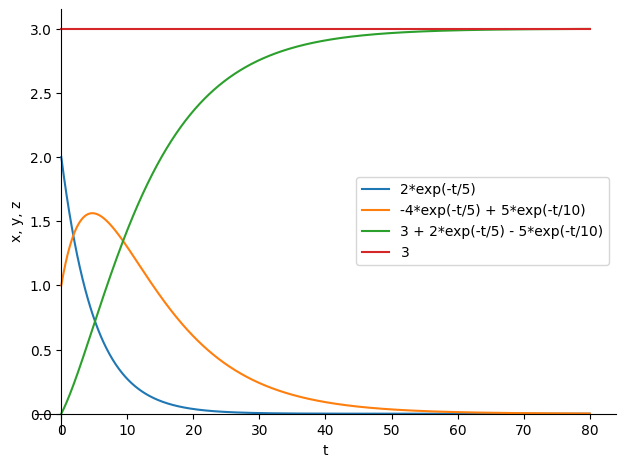

In [35]:
p = plot(sol[0].rhs, sol[1].rhs, sol[2].rhs, sol[0].rhs+sol[1].rhs+sol[2].rhs, (t, 0, 80), legend=True, show=True, xlabel='t', ylabel='x, y, z')

In [38]:
t_2_5 = solve(Eq(Rational(25, 10), sol[2].rhs))[0].evalf()
t_2_5

22.5994641753236

In [55]:
t_y_max = solve(Eq(0, sol[1].rhs.diff()))[0].evalf()
t_y_max

4.70003629245736

In [58]:
y_max = sol[1].rhs.subs(t, t_y_max)
y_max

1.56250000000000

## Задание 2.

Рассмотрим процесс опустошения бака с водой через отверстия в его дне. Предполагается, что скорость вытекания воды из бака пропорциональна объёму находящейся в нём воды.

Вода из первого бака, первоначальный объём которого составляет 2 литра, вытекает через два одинаковых отверстия в два других бака (второй и третий), расположенных на одном уровне. Суммарная скорость вытекания воды из первого бака характеризуется коэффициентом $k_1=0.1$. Вследствие одинаковых размеров отверстий вода поступает во второй и третий баки с одинаковой скоростью.

В начальный момент времени второй бак пуст, а в третьем содержится 1 литр воды. Из третьего бака вода также вытекает через отверстие в его дне. Скорость вытекания воды из третьего бака характеризуется коэффициентом $k_2=0.1$. Предполагается, что из второго бака вода не вытекает.

Составьте систему линейных дифференциальных уравнений, описывающую изменение объёмов воды во всех трёх баках, и определите момент времени, начиная с которого объём воды во втором баке становится больше объёма воды в третьем баке.

In [61]:
from sympy import *

t = symbols('t', nonnegative=True)
x = Function('x')
y = Function('y')
z = Function('z')

dx_t = Eq(x(t).diff(t), -Rational(1, 10)*x(t))
dy_t = Eq(y(t).diff(t), Rational(1, 10)*x(t))
dz_t = Eq(z(t).diff(t), Rational(1, 10)*x(t) - Rational(1, 10)*z(t))

sol = dsolve([dx_t, dy_t, dz_t], [x(t), y(t), z(t)], ics={x(0): 2, y(0): 0, z(0): 1})
print(sol)

[Eq(x(t), 2*exp(-t/10)), Eq(y(t), 2 - 2*exp(-t/10)), Eq(z(t), t*exp(-t/10)/5 + exp(-t/10))]


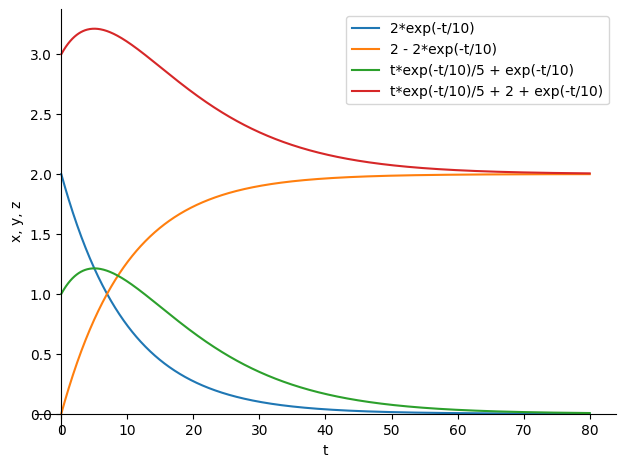

In [62]:
p = plot(sol[0].rhs, sol[1].rhs, sol[2].rhs, sol[0].rhs+sol[1].rhs+sol[2].rhs, (t, 0, 80), legend=True, show=True, xlabel='t', ylabel='x, y, z')

In [66]:
t_eq = solve(Eq(sol[1].rhs, sol[2].rhs))[0].evalf()
t_eq

8.57676673945899